# Huấn luyện kết hợp CIC-IDS2017 và InSDN: M1 / M2 / M3

Dùng đúng `run_three_models` của CLI `train_all.py --combined`. M3 học một Stacking mới từ dữ liệu cả hai nguồn, không ghép hai model M1/M2 đã lưu. M1/M2 chạy cùng protocol để so sánh trên đúng các hàng test.

**Bài toán hiện tại là BENIGN/ATTACK.** Hai taxonomy gốc khác nhau; notebook không tự tạo M3 đa lớp. Huấn luyện dùng mẫu có class cap, không phải toàn bộ mọi hàng CSV.

Mặc định DO_TRAIN=False: đọc artifact. Để train thật, chọn tham số và OUT mới, đổi DO_TRAIN=True, Restart Kernel rồi Run All. Huấn luyện chạy cả ba cấu hình và có thể mất vài phút.

In [1]:
%matplotlib inline
from argparse import Namespace
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/train_all.py').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from three_models import run_three_models
from features import FEATURES
DO_TRAIN = False
SEED, CAP, TREES, FOLDS = 42, 5000, 120, 3
TUNE, STACK_SEARCH = True, False
CIC_DATA = ROOT / 'data/MachineLearningCVE'
INSDN_DATA = ROOT / 'data/InSDN(2020)'
OUT = ROOT / f'experiments/notebook-combined-seed{SEED}'
RESULT = ROOT / f'experiments/completion-20261110/three-models-seed{SEED}'
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
display(pd.Series({'training_enabled': DO_TRAIN, 'seed': SEED, 'cap_per_binary_class_per_source': CAP,
                   'trees': TREES, 'folds': FOLDS, 'baseline_tuning': TUNE, 'meta_search': STACK_SEARCH,
                   'new_output': str(OUT)}, name='configuration').to_frame())

,configuration
training_enabled,False
seed,42
cap_per_binary_class_per_source,5000
trees,120
folds,3
baseline_tuning,True
meta_search,False
new_output,D:\Downloads\network-stacking-ids-20261107\net...


## 1. Hai nguồn và hợp đồng feature

Pipeline đọc mỗi nguồn theo chunk, ánh xạ tên cột về 12 feature chung, đổi Normal/BENIGN thành BENIGN và subtype hợp lệ thành ATTACK trước sampling. Loại missing toàn bộ feature, vector trùng/mâu thuẫn trong mẫu; khử trùng giữa hai nguồn trước split. IP, Label và source_dataset không phải feature.

In [2]:
display(pd.DataFrame([
    {'configuration': 'M1', 'training_sources': 'CIC', 'input': str(CIC_DATA)},
    {'configuration': 'M2', 'training_sources': 'InSDN', 'input': str(INSDN_DATA)},
    {'configuration': 'M3', 'training_sources': 'CIC + InSDN', 'input': 'Union hai development set sau cleanup/split'}]))
display(pd.DataFrame({'shared_features': FEATURES}))

,configuration,training_sources,input
0,M1,CIC,D:\Downloads\network-stacking-ids-20261107\net...
1,M2,InSDN,D:\Downloads\network-stacking-ids-20261107\net...
2,M3,CIC + InSDN,Union hai development set sau cleanup/split


,shared_features
0,Destination Port
1,Flow Duration
2,Total Fwd Packets
3,Total Backward Packets
4,Total Length of Fwd Packets
5,Total Length of Bwd Packets
6,FIN Flag Count
7,SYN Flag Count
8,RST Flag Count
9,PSH Flag Count


## 2. Huấn luyện bằng pipeline chung

Mỗi nguồn chia stratified random 60/20/20. M1 chỉ học CIC, M2 chỉ học InSDN, M3 nối hai train và hai validation. Baseline chọn bằng CV train; stack chọn bằng validation, refit train+validation rồi đánh giá test.

M3 chỉ fit một lần ở bước refit cuối, rồi đánh giá Test CIC, Test InSDN và test gộp. Metrics test gộp tính trên các hàng nối lại, không trung bình hai F1. STACK_SEARCH=True tìm C/weight meta bằng train OOF và validation; mặc định False khớp lượt đã lưu.

In [3]:
if DO_TRAIN:
    if OUT.exists():
        raise ValueError('OUT đã tồn tại. Chọn OUT mới trước khi train.')
    args = Namespace(cic_data=str(CIC_DATA), insdn_data=str(INSDN_DATA), out=str(OUT),
                     combined=True, max_per_class=CAP, trees=TREES, seed=SEED,
                     folds=FOLDS, tune=TUNE, stack_search=STACK_SEARCH)
    run_three_models(args)
    RESULT = OUT
else:
    display(Markdown(f'Đọc artifact `{RESULT.relative_to(ROOT)}`; không train lại.'))
protocol = read_json(RESULT / 'protocol.json')
completed = read_json(RESULT / 'completed.json')
assert completed['result_rows'] == 30
assert set(completed['configurations']) == {'M1', 'M2', 'M3'}

Đọc artifact `experiments\completion-20261110\three-models-seed42`; không train lại.

## 3. Sampling, cleanup và split

Số đếm nhãn gốc là toàn CSV; train/test thuộc mẫu đã cleanup. Class cap thay đổi cả tỷ lệ test. Hai subtype khác tên không tự trở thành cùng loại tấn công chỉ vì cùng chuyển thành ATTACK.

In [4]:
display(pd.DataFrame({source: data['raw_class_counts'] for source, data in protocol['sources'].items()}).fillna(0).astype(int))
cleanup = protocol['cleanup_and_splits']
display(pd.DataFrame({'before_global_cleanup': cleanup['rows_before'], 'after_global_cleanup': cleanup['rows_after']}))
display(pd.Series({key: cleanup[key] for key in ['conflicting_rows_removed', 'duplicate_rows_removed', 'duplicate_policy']}, name='global_cleanup').to_frame())
counts = [{'source': source, 'partition': part, **labels}
          for source, parts in cleanup['split_counts'].items() for part, labels in parts.items()]
display(pd.DataFrame(counts))

,cicids2017,insdn
BENIGN,2273097,0
DDoS,128027,73529
PortScan,158930,0
Bot,1966,0
Infiltration,36,0
Web Attack � Brute Force,1507,0
Web Attack � XSS,652,0
Web Attack � Sql Injection,21,0
FTP-Patator,7938,0
SSH-Patator,5897,0


,before_global_cleanup,after_global_cleanup
cicids2017,9408,9408
insdn,7423,7423


,global_cleanup
conflicting_rows_removed,0
duplicate_rows_removed,0
duplicate_policy,Remove contradictory binary labels; keep first...


,source,partition,BENIGN,ATTACK
0,cicids2017,train,2949,2695
1,cicids2017,validation,984,898
2,cicids2017,test,984,898
3,insdn,train,2971,1482
4,insdn,validation,991,494
5,insdn,test,991,494


## 4. Xác minh M3 học dữ liệu gộp và dùng test chung

Đối chiếu số hàng M3 với tổng hai nguồn và hash test M1/M3, M2/M3. Hash chứng minh dùng cùng vector test, không chứng minh các phiên mạng độc lập hoặc feature-extractor parity.

In [5]:
models = {name: read_json(RESULT / name / 'protocol.json') for name in ['M1', 'M2', 'M3']}
for part in ['train', 'validation']:
    for label in ['BENIGN', 'ATTACK']:
        assert models['M3']['split_class_counts'][part][label] == sum(cleanup['split_counts'][source][part][label] for source in ['cicids2017', 'insdn'])
assert models['M1']['split_feature_sha256']['cicids2017'] == models['M3']['split_feature_sha256']['cicids2017']
assert models['M2']['split_feature_sha256']['insdn'] == models['M3']['split_feature_sha256']['insdn']
display(pd.DataFrame([{'configuration': name, 'sources': ', '.join(p['data']['training_sources']),
                       'train_rows': sum(p['split_class_counts']['train'].values()),
                       'validation_rows': sum(p['split_class_counts']['validation'].values()),
                       'final_fit_rows': sum(p['split_class_counts']['train'].values())+sum(p['split_class_counts']['validation'].values()),
                       'selected_stack': p['selected_stack']} for name, p in models.items()]))
display(Markdown('Đã kiểm tra: **M3 = union hai nguồn; hai test nguồn được tái sử dụng chính xác.**'))

,configuration,sources,train_rows,validation_rows,final_fit_rows,selected_stack
0,M1,cicids2017,5644,1882,7526,trees
1,M2,insdn,4453,1485,5938,trees
2,M3,"cicids2017, insdn",10097,3367,13464,trees


Đã kiểm tra: **M3 = union hai nguồn; hai test nguồn được tái sử dụng chính xác.**

## 5. Baseline và Stacking trên cùng test

Một seed có 30 hàng metrics: M1 6 + M2 6 + M3 3 test × 6 thuật toán. Để có mean/SD, chạy đủ seed 7/21/42 với OUT riêng rồi dùng summarize.py; không chọn seed tốt nhất để báo cáo.

,configuration,test_dataset,algorithm,accuracy,macro_f1,benign_false_positive_rate,attack_false_negative_rate
0,M1,cicids2017,dt,0.989904,0.989881,0.007114,0.013363
1,M1,cicids2017,rf,0.992561,0.992544,0.005081,0.010022
2,M1,cicids2017,xgb,0.990967,0.990947,0.007114,0.011136
3,M1,cicids2017,lgbm,0.992030,0.992013,0.008130,0.007795
4,M1,cicids2017,lr,0.858661,0.858442,0.216463,0.059020
5,M1,cicids2017,stacking,0.991498,0.991480,0.007114,0.010022
6,M2,insdn,dt,1.000000,1.000000,0.000000,0.000000
7,M2,insdn,rf,0.998653,0.998485,0.002018,0.000000
8,M2,insdn,xgb,0.999327,0.999242,0.001009,0.000000
9,M2,insdn,lgbm,1.000000,1.000000,0.000000,0.000000


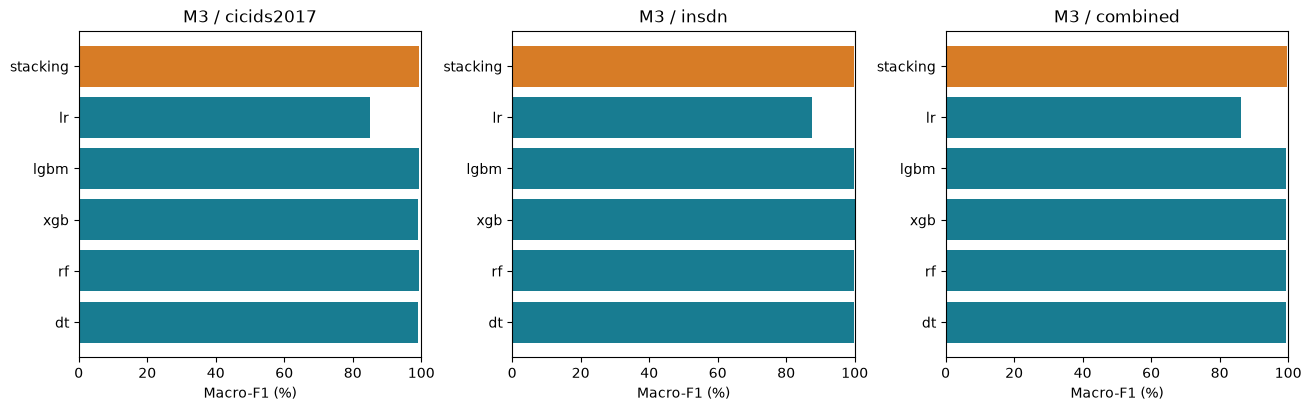

In [6]:
comparison = pd.read_csv(RESULT / 'comparison_all.csv')
assert len(comparison) == 30
assert not comparison.duplicated(['configuration', 'test_dataset', 'algorithm']).any()
display(comparison[['configuration', 'test_dataset', 'algorithm', 'accuracy', 'macro_f1', 'benign_false_positive_rate', 'attack_false_negative_rate']])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
for ax, source in zip(axes, ['cicids2017', 'insdn', 'combined']):
    scores = comparison.loc[comparison.configuration.eq('M3') & comparison.test_dataset.eq(source)].set_index('algorithm').macro_f1 * 100
    ax.barh(scores.index, scores, color=['#d77c26' if name == 'stacking' else '#187c91' for name in scores.index])
    ax.set(xlim=(0, 100), xlabel='Macro-F1 (%)', title=f'M3 / {source}')
plt.show()

## 6. Confusion matrix của M3 trên ba test

Hàng là nhãn thật, cột là dự đoán; lấy thứ tự nhãn từ CSV. Accuracy so với ground truth; smoke match so với dự đoán đã lưu để kiểm tra tái lập.

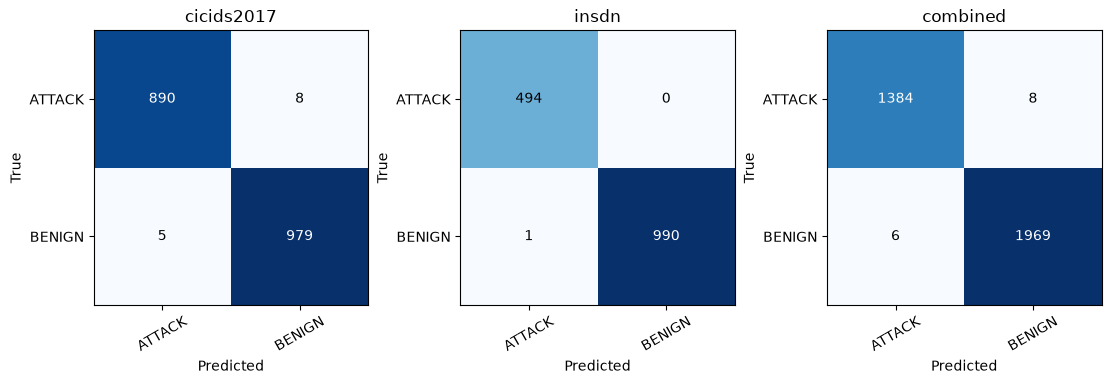

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout='constrained')
for ax, source in zip(axes, ['cicids2017', 'insdn', 'combined']):
    matrix = pd.read_csv(RESULT / 'M3' / source / 'confusion_stacking.csv', index_col=0)
    ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=30)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted', ylabel='True', title=source)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, str(matrix.iloc[i,j]), ha='center', va='center', color='white' if matrix.iloc[i,j] > matrix.to_numpy().max()/2 else 'black')
plt.show()

## 7. Model đầu ra và kiểm chứng

Artifact gồm preprocessing, model, feature và nhãn. Chỉ load joblib tự tạo/đáng tin cậy. Cell sau chỉ in lệnh, không ghi thêm evaluation hoặc tự bắt gói tin.

In [8]:
display(pd.DataFrame([{'configuration': name, 'model': str(RESULT / name / 'models/stacking_ids.joblib'),
                       'exists': (RESULT / name / 'models/stacking_ids.joblib').is_file()} for name in ['M1', 'M2', 'M3']]))
relative = RESULT.relative_to(ROOT).as_posix()
print(fr'.\.venv\Scripts\python.exe src/check_model.py --model {relative}/M3/models/stacking_ids.joblib --csv {relative}/M3/cicids2017/smoke_test.csv')
print(fr'.\.venv\Scripts\python.exe src/evaluate_model.py --model {relative}/M3/models/stacking_ids.joblib --csv {relative}/splits/cicids2017/test.csv --out experiments/evaluate-combined-cic-new')

,configuration,model,exists
0,M1,D:\Downloads\network-stacking-ids-20261107\net...,True
1,M2,D:\Downloads\network-stacking-ids-20261107\net...,True
2,M3,D:\Downloads\network-stacking-ids-20261107\net...,True


.\.venv\Scripts\python.exe src/check_model.py --model experiments/completion-20261110/three-models-seed42/M3/models/stacking_ids.joblib --csv experiments/completion-20261110/three-models-seed42/M3/cicids2017/smoke_test.csv
.\.venv\Scripts\python.exe src/evaluate_model.py --model experiments/completion-20261110/three-models-seed42/M3/models/stacking_ids.joblib --csv experiments/completion-20261110/three-models-seed42/splits/cicids2017/test.csv --out experiments/evaluate-combined-cic-new


## Giới hạn

- Tên cột chung chưa chứng minh cùng cách đo feature; cần parity trước khi suy rộng sang lab.
- Class cap/cleanup thay đổi phân bố, random split chưa tách phiên/thời gian, M3 đã thấy hai miền trong train.
- M3 có nhiều hàng học hơn M1/M2. Xem size-ablation và experiment.ipynb để so sánh cùng cỡ mẫu.
- Tuning trước OOF chưa phải nested CV hoàn chỉnh; test chỉ báo cáo, ES không được bảo đảm thắng baseline.
- M3 hiện là nhị phân. Kết hợp đa lớp cần taxonomy chung đã kiểm chứng, notebook không tự đổi bài toán.
- Xem THREE_MODELS.md, STACKING_SCOPE.md, CURRENT_RESULTS.md. Kết quả CSV offline chưa phải độ chính xác live.